# MARL Notebook: CityLearn

Sections included:
- Visualization of the buildings schema
- Visualization of state space
- Visualization of action space
- Reward function details
- KPI analysis
- SAC multi-agent training loop with TensorBoard logging + CityLearn `ui_exports`

# Modules

## Install

In [ ]:
# for colab
!pip install citylearn ray[rllib] matplotlib ipywidgets tensorboard gputil

## Import

In [1]:
import json
import io
import logging
import warnings
from datetime import datetime
from pathlib import Path
import zipfile
import requests
import contextlib


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ray
import torch
from IPython.display import display
from tqdm.auto import tqdm

from citylearn.wrappers import (
    ClippedObservationWrapper,
    NormalizedObservationWrapper,
    RLlibMultiAgentEnv,
)
from ray.rllib.algorithms.sac import SACConfig
from ray.rllib.policy.policy import PolicySpec

warnings.filterwarnings('ignore', category=DeprecationWarning)
logging.getLogger('ray.rllib.env.multi_agent_env').setLevel(logging.ERROR)
logging.getLogger('ray.rllib.utils.replay_buffers.multi_agent_prioritized_replay_buffer').setLevel(logging.ERROR)
plt.style.use('seaborn-v0_8-whitegrid')

from torch.utils.tensorboard import SummaryWriter

d:\AI Projects\rl-city-learn\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-03-07 12:46:57,488	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-03-07 12:47:06,231	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


# Data

## utils

In [2]:
def download_dataset_archive(citylearn_version: str, dataset_name: str, schema_path: Path):
    
    cache_dir = schema_path.parent
    cache_dir.mkdir(parents=True, exist_ok=True)
    zip_url = f'https://github.com/intelligent-environments-lab/CityLearn/archive/refs/tags/{citylearn_version}.zip'
    response = requests.get(zip_url, stream=True, timeout=120)
    response.raise_for_status()

    dataset_prefix = f"CityLearn-{citylearn_version.lstrip('v')}/data/datasets/{dataset_name}/"
    with zipfile.ZipFile(io.BytesIO(response.content)) as zf:
        matched = [name for name in zf.namelist() if name.startswith(dataset_prefix)]
        if not matched:
            raise FileNotFoundError(f'Dataset folder not found in archive: {dataset_prefix}')

        for member in matched:
            relative = member[len(dataset_prefix):]
            if not relative:
                continue
            dest = cache_dir / relative
            dest.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(member) as src, open(dest, 'wb') as dst:
                dst.write(src.read())

## config

In [3]:
# number of buildings to name mapping
DATASETS = {
    '3': 'citylearn_challenge_2023_phase_2_local_evaluation',
    '6': 'citylearn_challenge_2023_phase_3_3'
}

In [4]:
PROJECT_ROOT = Path.cwd().resolve().parent.resolve()
CITYLEARN_VERSION = 'v2.5.0'
DATASET_SIZE = '3'
DATASET_NAME = DATASETS[DATASET_SIZE]

LOCAL_SCHEMA_PATH = (
    PROJECT_ROOT
    / 'datasets'
    / DATASET_NAME
    / 'schema.json'
)
AUTO_DOWNLOAD_DATASET_IF_MISSING = True

In [ ]:
REWARD_FUNCTION_TYPE = 'citylearn.reward_function.SolarPenaltyReward'
REWARD_NAME = 'solar_penalty'
REWARD_FUNCTION_ATTRIBUTES = {}
FORCE_REWARD_OVERRIDE = True

UI_EXPORT_ROOT = PROJECT_ROOT / 'outputs' / 'sac' / REWARD_NAME / DATASET_SIZE / 'ui_exports'
TENSORBOARD_ROOT = PROJECT_ROOT / 'outputs' / 'sac' / REWARD_NAME / DATASET_SIZE / 'tensorboard'
CHECKPOINT_ROOT = PROJECT_ROOT / 'outputs' / 'sac' / REWARD_NAME / DATASET_SIZE / 'checkpoints'
SCHEMA_OVERRIDE_ROOT = PROJECT_ROOT / 'outputs' / 'sac' / REWARD_NAME / DATASET_SIZE / 'schemas'

## download

In [7]:
if not LOCAL_SCHEMA_PATH.exists() and AUTO_DOWNLOAD_DATASET_IF_MISSING:
    print('Local dataset not found. Downloading CityLearn archive...')
    download_dataset_archive(CITYLEARN_VERSION, DATASET_NAME, LOCAL_SCHEMA_PATH)

if not LOCAL_SCHEMA_PATH.exists():
    raise FileNotFoundError(
        f'Schema not found at {LOCAL_SCHEMA_PATH}. '
        'Set AUTO_DOWNLOAD_DATASET_IF_MISSING=True or cache dataset manually.'
    )

for d in [UI_EXPORT_ROOT, TENSORBOARD_ROOT, CHECKPOINT_ROOT, SCHEMA_OVERRIDE_ROOT]:
    d.mkdir(parents=True, exist_ok=True)

with LOCAL_SCHEMA_PATH.open('r', encoding='utf-8') as f:
    base_schema_dict = json.load(f)

base_schema_dict['root_directory'] = str(LOCAL_SCHEMA_PATH.parent)

active_reward = base_schema_dict.get('reward_function', {})
if FORCE_REWARD_OVERRIDE:
    active_reward = {'type': REWARD_FUNCTION_TYPE, 'attributes': REWARD_FUNCTION_ATTRIBUTES}
    base_schema_dict['reward_function'] = active_reward

GENERATED_SCHEMA_PATH = SCHEMA_OVERRIDE_ROOT / f'{DATASET_NAME}_reward_override.json'
with GENERATED_SCHEMA_PATH.open('w', encoding='utf-8') as f:
    json.dump(base_schema_dict, f, indent=2)

SCHEMA_SOURCE = GENERATED_SCHEMA_PATH

print(f'Schema source: {SCHEMA_SOURCE}')
print(f'Active reward: {active_reward}')
print(f'UI exports directory: {UI_EXPORT_ROOT}')
print(f'TensorBoard root: {TENSORBOARD_ROOT}')
print(f'Checkpoint root: {CHECKPOINT_ROOT}')

Local dataset not found. Downloading CityLearn archive...
Schema source: D:\AI Projects\rl-city-learn\outputs\indep-sac\indep-sac\3\schemas\citylearn_challenge_2023_phase_2_local_evaluation_reward_override.json
Active reward: {'type': 'citylearn.reward_function.IndependentSACReward', 'attributes': {}}
UI exports directory: D:\AI Projects\rl-city-learn\outputs\indep-sac\indep-sac\3\ui_exports
TensorBoard root: D:\AI Projects\rl-city-learn\outputs\indep-sac\indep-sac\3\tensorboard
Checkpoint root: D:\AI Projects\rl-city-learn\outputs\indep-sac\indep-sac\3\checkpoints


# Environment

In [8]:
def make_env_config(render_mode='none', render_session_name=None):
    env_kwargs = {
        'schema': SCHEMA_SOURCE,
        'render_mode': render_mode,
        'render_directory': UI_EXPORT_ROOT,
    }
    if render_session_name is not None:
        env_kwargs['render_session_name'] = render_session_name

    return {
        'env_kwargs': env_kwargs,
        'wrappers': [NormalizedObservationWrapper, ClippedObservationWrapper],
    }

def make_env(render_mode='none', render_session_name=None):
    return RLlibMultiAgentEnv(
        make_env_config(render_mode=render_mode, render_session_name=render_session_name)
    )

def unwrap_citylearn_env(env):
    current = env
    while hasattr(current, 'env'):
        current = current.env
    return current

def load_schema_dict(schema_source):
    schema_path = Path(schema_source)
    if schema_path.exists():
        with schema_path.open('r', encoding='utf-8') as f:
            return json.load(f)
    raise FileNotFoundError(
        'Local schema.json not found. Cache the dataset first or set SCHEMA_SOURCE to a local schema file.'
    )

env = make_env()
obs, _ = env.reset()
agent_ids = sorted(obs.keys())
base_env = unwrap_citylearn_env(env)
building_names = [b.name for b in base_env.buildings]

print(f'Agents: {agent_ids}')
print(f'Buildings: {building_names}')

Agents: ['agent_0', 'agent_1', 'agent_2']
Buildings: ['Building_1', 'Building_2', 'Building_3']


d:\AI Projects\rl-city-learn\.venv\lib\site-packages\citylearn\dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepath)[

# Viz

## Buildings Schema
Read `schema.json`, extract core per-building attributes, and visualize key capacities/powers.

In [9]:
schema_dict = load_schema_dict(SCHEMA_SOURCE)

building_rows = []
for building_name, cfg in schema_dict['buildings'].items():
    building_rows.append({
        'building': building_name,
        'cooling_nominal_power_kw': cfg['cooling_device']['attributes']['nominal_power'],
        'dhw_device_nominal_power_kw': cfg['dhw_device']['attributes']['nominal_power'],
        'dhw_storage_capacity_kwh': cfg['dhw_storage']['attributes']['capacity'],
        'battery_capacity_kwh': cfg['electrical_storage']['attributes']['capacity'],
        'battery_nominal_power_kw': cfg['electrical_storage']['attributes']['nominal_power'],
        'pv_nominal_power_kw': cfg['pv']['attributes']['nominal_power'],
    })

building_df = pd.DataFrame(building_rows).sort_values('building').reset_index(drop=True)
display(building_df)

,building,cooling_nominal_power_kw,dhw_device_nominal_power_kw,dhw_storage_capacity_kwh,battery_capacity_kwh,battery_nominal_power_kw,pv_nominal_power_kw
0,Building_1,4.109620,4.861171,2.282676,4.0,3.32,2.4
1,Building_2,2.252524,3.681978,1.655921,4.0,3.32,1.2
2,Building_3,2.777702,6.286403,2.842340,3.3,1.61,2.4


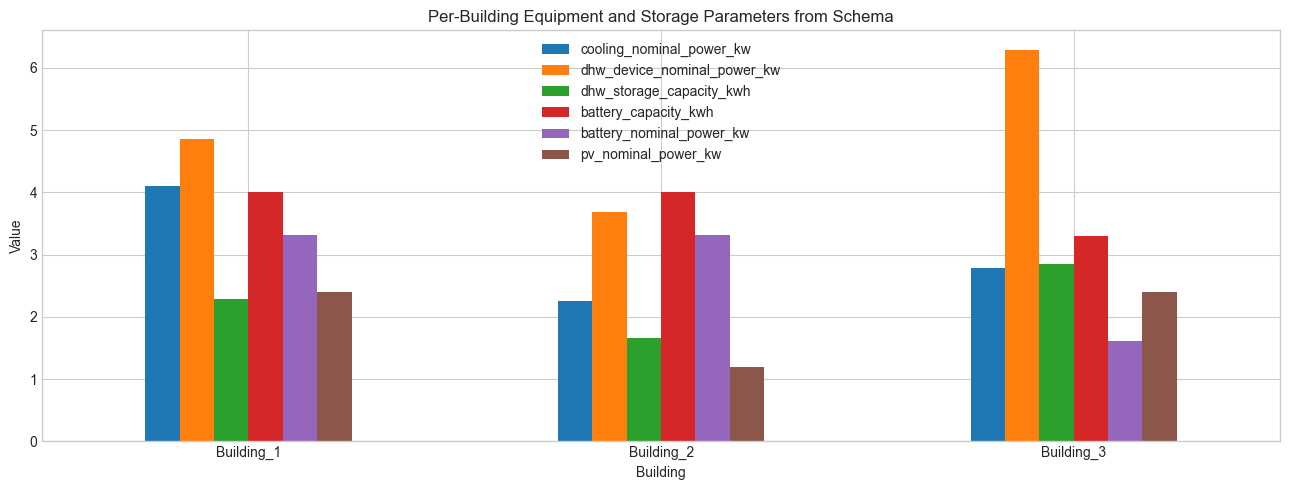

In [10]:
plot_columns = [
    'cooling_nominal_power_kw',
    'dhw_device_nominal_power_kw',
    'dhw_storage_capacity_kwh',
    'battery_capacity_kwh',
    'battery_nominal_power_kw',
    'pv_nominal_power_kw',
]

ax = building_df.set_index('building')[plot_columns].plot(kind='bar', figsize=(13, 5))
ax.set_title('Per-Building Equipment and Storage Parameters from Schema')
ax.set_ylabel('Value')
ax.set_xlabel('Building')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Reward Function
The active reward comes from the generated schema (`SCHEMA_SOURCE`). Update `REWARD_FUNCTION_TYPE` and `REWARD_FUNCTION_ATTRIBUTES` in the config cell to switch reward.

In [11]:
reward_cfg = schema_dict.get('reward_function', {})
reward_type = reward_cfg.get('type', 'unknown')
reward_attributes = reward_cfg.get('attributes', {})

reward_df = pd.DataFrame({
    'reward_parameter': list(reward_attributes.keys()),
    'value': list(reward_attributes.values()),
})

print(f"Configured reward override type: {REWARD_FUNCTION_TYPE}")
print(f"Configured reward override attributes: {REWARD_FUNCTION_ATTRIBUTES}")
print(f"Reward function type loaded by env: {reward_type}")
if len(reward_df) > 0:
    display(reward_df)
else:
    print('No reward attributes found in schema.')

Configured reward override type: citylearn.reward_function.IndependentSACReward
Configured reward override attributes: {}
Reward function type loaded by env: citylearn.reward_function.IndependentSACReward
No reward attributes found in schema.


## State Space

Using wrapped environment observations (`NormalizedObservationWrapper` + `ClippedObservationWrapper`).


In [12]:
def state_feature_group(feature_name):
    if 'pricing' in feature_name:
        return 'pricing'
    if 'irradiance' in feature_name or 'solar' in feature_name:
        return 'solar_weather'
    if 'temperature' in feature_name or 'humidity' in feature_name:
        return 'temperature_humidity'
    if 'storage' in feature_name or 'soc' in feature_name:
        return 'storage_state'
    if 'demand' in feature_name or 'load' in feature_name or 'consumption' in feature_name:
        return 'demand_load'
    if 'hour' in feature_name or 'day' in feature_name or 'month' in feature_name:
        return 'time_calendar'
    if 'occupant' in feature_name or 'power_outage' in feature_name:
        return 'occupancy_outage'
    return 'other'

first_agent = agent_ids[0]
wrapped_observation_names = env.env.observation_names[0]
obs_space = env.observation_space[first_agent]

state_df = pd.DataFrame({
    'feature': wrapped_observation_names,
    'low': obs_space.low,
    'high': obs_space.high,
    'sample_value_t0': obs[first_agent],
})
state_df['range'] = state_df['high'] - state_df['low']
state_df['group'] = state_df['feature'].map(state_feature_group)

print(f'Observation dimension per agent: {obs_space.shape[0]}')
display(state_df)

Observation dimension per agent: 32


,feature,low,high,sample_value_t0,range,group
0,day_type_cos,0.0,1.0,0.356896,1.0,time_calendar
1,day_type_sin,0.0,1.0,0.000000,1.0,time_calendar
2,hour_cos,0.0,1.0,0.982963,1.0,time_calendar
3,hour_sin,0.0,1.0,0.629410,1.0,time_calendar
4,outdoor_dry_bulb_temperature,0.0,1.0,0.173178,1.0,temperature_humidity
5,outdoor_dry_bulb_temperature_predicted_1,0.0,1.0,0.184908,1.0,temperature_humidity
6,outdoor_dry_bulb_temperature_predicted_2,0.0,1.0,0.840306,1.0,temperature_humidity
7,outdoor_dry_bulb_temperature_predicted_3,0.0,1.0,0.341111,1.0,temperature_humidity
8,diffuse_solar_irradiance,0.0,1.0,0.000000,1.0,solar_weather
9,diffuse_solar_irradiance_predicted_1,0.0,1.0,0.118430,1.0,solar_weather


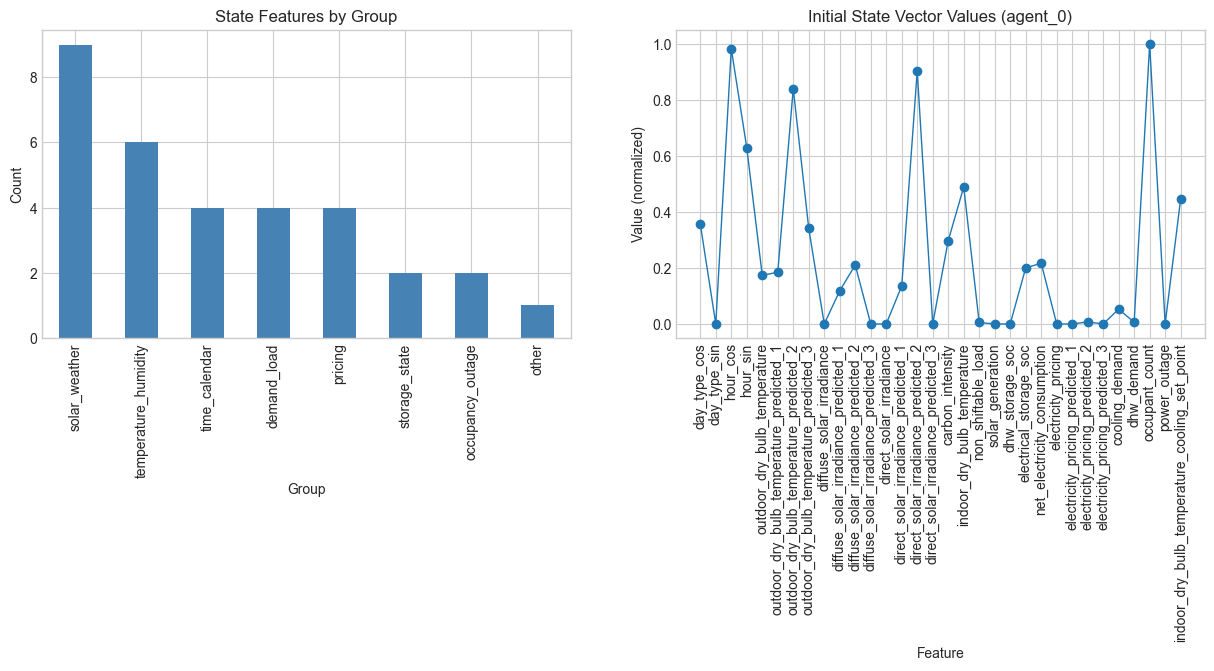

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

state_df['group'].value_counts().sort_values(ascending=False).plot(
    kind='bar', ax=axes[0], color='steelblue'
)
axes[0].set_title('State Features by Group')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Group')

axes[1].plot(state_df['feature'], state_df['sample_value_t0'], marker='o', linewidth=1)
axes[1].set_title(f'Initial State Vector Values ({first_agent})')
axes[1].set_ylabel('Value (normalized)')
axes[1].set_xlabel('Feature')
axes[1].tick_params(axis='x', rotation=90)

plt.show()

## Action Space
Inspect action names and bounds per building agent.

Action dimension per agent: 3


,action,low,high,range
0,dhw_storage,-1.0,1.0,2.0
1,electrical_storage,-1.0,1.0,2.0
2,cooling_device,0.0,1.0,1.0


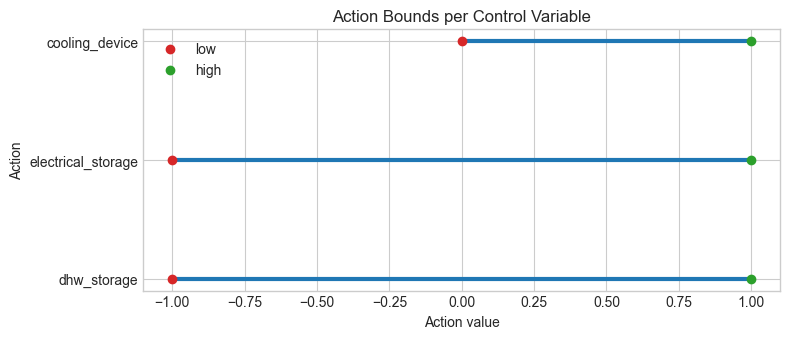

In [14]:
action_names = env.env.action_names[0]
act_space = env.action_space[first_agent]

action_df = pd.DataFrame({
    'action': action_names,
    'low': act_space.low,
    'high': act_space.high,
})
action_df['range'] = action_df['high'] - action_df['low']

print(f'Action dimension per agent: {act_space.shape[0]}')
display(action_df)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hlines(y=action_df['action'], xmin=action_df['low'], xmax=action_df['high'], color='tab:blue', linewidth=3)
ax.scatter(action_df['low'], action_df['action'], color='tab:red', label='low', zorder=3)
ax.scatter(action_df['high'], action_df['action'], color='tab:green', label='high', zorder=3)
ax.set_title('Action Bounds per Control Variable')
ax.set_xlabel('Action value')
ax.set_ylabel('Action')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

##  KPIs
Run one episode with a baseline random policy and compute CityLearn KPIs.

In [15]:
def rollout_episode(multi_env, policy_fn=None):
    observations, _ = multi_env.reset()
    episode_rewards = {agent_id: 0.0 for agent_id in observations}

    while not multi_env.terminated:
        if policy_fn is None:
            actions = {agent_id: multi_env.action_space[agent_id].sample() for agent_id in observations}
        else:
            actions = policy_fn(observations)

        observations, rewards, _, _, _ = multi_env.step(actions)
        for agent_id, reward in rewards.items():
            episode_rewards[agent_id] += float(reward)

    return episode_rewards

def compute_kpis(multi_env):
    raw = unwrap_citylearn_env(multi_env).evaluate().copy()
    table = (
        raw.pivot(index='cost_function', columns='name', values='value')
        .sort_index()
        .round(4)
    )
    return raw, table

In [16]:
baseline_env = make_env(render_mode='none')
baseline_rewards = rollout_episode(baseline_env, policy_fn=None)
baseline_raw_kpis, baseline_kpi_table = compute_kpis(baseline_env)

print('Random-policy episode rewards per agent:')
print(baseline_rewards)
display(baseline_kpi_table)

baseline_env.close()

d:\AI Projects\rl-city-learn\.venv\lib\site-packages\citylearn\dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepath)[

Random-policy episode rewards per agent:
{'agent_0': -1752.0331698637456, 'agent_1': -1097.0817687660456, 'agent_2': -1440.1621643416584}


name,Building_1,Building_2,Building_3,District
cost_function,,,,
all_time_peak_average,NaN,NaN,NaN,0.9983
annual_normalized_unserved_energy_total,0.0178,0.0170,0.0154,0.0167
carbon_emissions_total,1.6876,1.7874,1.5377,1.6709
cost_total,1.6238,1.7356,1.5074,1.6222
daily_one_minus_load_factor_average,NaN,NaN,NaN,0.8307
daily_peak_average,NaN,NaN,NaN,1.2975
discomfort_cold_delta_average,8.4276,3.6170,2.8301,4.9582
discomfort_cold_delta_maximum,16.1261,11.8866,6.6203,11.5444
discomfort_cold_delta_minimum,0.0000,0.0000,0.0000,0.0000


# Training (Loop, Tensorboard, CityLearn UI Export)

## SAC (Centralized)

### config

In [ ]:
N_ITERATIONS = 750
LOG_INTERVAL = 10
EVAL_INTERVAL = 50
NUM_GPUS = 1 if torch.cuda.is_available() else 0

print(f'NUM_GPUS set to: {NUM_GPUS}')

NUM_GPUS set to: 1


In [68]:
sac_config = (
    SACConfig()
    .api_stack(enable_rl_module_and_learner=False, enable_env_runner_and_connector_v2=False)
    .training(
        replay_buffer_config={
            'type': 'MultiAgentPrioritizedReplayBuffer',
            'capacity': 1_000_000,
            'prioritized_replay_alpha': 0.6,
            'prioritized_replay_beta': 0.4,
            'prioritized_replay_eps': 1e-6,
        }
    )
    .resources(num_gpus=NUM_GPUS)
    .environment(RLlibMultiAgentEnv, env_config=make_env_config(render_mode='none'))
    .multi_agent(
        policies={'shared_policy': PolicySpec()},
        policy_mapping_fn=lambda agent_id, *args, **kwargs: 'shared_policy',
    )
    .env_runners(
        num_env_runners=0,
        rollout_fragment_length='auto',
        batch_mode='truncate_episodes',
        sample_timeout_s=600
    )
    .framework('torch')
)

### utils

In [ ]:
def log_scalar(writer, tag, value, step):
    if isinstance(value, (int, float, np.integer, np.floating)) and np.isfinite(value):
        writer.add_scalar(tag, float(value), step)

def get_eval_score(district_kpis_df):
    cost_total_row = district_kpis_df[district_kpis_df['cost_function'] == 'cost_total']
    if len(cost_total_row) > 0 and np.isfinite(cost_total_row.iloc[0]['value']):
        return float(cost_total_row.iloc[0]['value']), 'cost_total'

    valid_values = district_kpis_df['value'].replace([np.inf, -np.inf], np.nan).dropna()
    if len(valid_values) == 0:
        return np.nan, 'undefined'

    return float(valid_values.mean()), 'district_mean'

def extract_checkpoint_path(checkpoint_info):
    if isinstance(checkpoint_info, str):
        return checkpoint_info

    checkpoint_obj = getattr(checkpoint_info, 'checkpoint', None)
    if checkpoint_obj is not None:
        return getattr(checkpoint_obj, 'path', str(checkpoint_obj))

    return str(checkpoint_info)

### loop

In [69]:
run_name = f'iter_{N_ITERATIONS}_eval_{EVAL_INTERVAL}_{datetime.now():%Y%m%d_%H%M%S}'
tb_log_dir = TENSORBOARD_ROOT / run_name
checkpoint_run_dir = CHECKPOINT_ROOT / run_name
checkpoint_run_dir.mkdir(parents=True, exist_ok=True)
writer = SummaryWriter(log_dir=str(tb_log_dir))

VERBOSE = False

In [73]:
algo = sac_config.build()

history_rows = []
latest_kpi_table = None
best_eval_score = None
best_eval_metric = None
best_checkpoint_path = None

pbar = tqdm(range(1, N_ITERATIONS + 1), desc='SAC Training', unit='iter')
for i in pbar:
    result = algo.train()

    mean_reward = result['env_runners']['episode_reward_mean']
    sampled_this_iter = result.get('num_env_steps_sampled_this_iter', 0)
    trained_this_iter = result.get('num_env_steps_trained_this_iter', 0)
    total_sampled = result.get('num_env_steps_sampled', 0)
    total_trained = result.get('num_env_steps_trained', 0)
    timesteps_total = result.get('timesteps_total', 0)

    row = {
        'iteration': i,
        'episode_reward_mean': mean_reward,
        'sampled_this_iter': sampled_this_iter,
        'trained_this_iter': trained_this_iter,
        'total_sampled': total_sampled,
        'total_trained': total_trained,
        'eval_score': np.nan,
        'eval_metric': None,
        'is_best_checkpoint': False,
    }

    log_scalar(writer, 'train/episode_reward_mean', mean_reward, i)
    log_scalar(writer, 'train/sampled_this_iter', sampled_this_iter, i)
    log_scalar(writer, 'train/trained_this_iter', trained_this_iter, i)
    log_scalar(writer, 'train/total_sampled', total_sampled, i)
    log_scalar(writer, 'train/total_trained', total_trained, i)

    learner_info = result.get('info', {}).get('learner', {})
    for policy_id, metrics in learner_info.items():
        if not isinstance(metrics, dict):
            continue
        for metric_name in ['actor_loss', 'critic_loss', 'alpha_loss', 'alpha_value',
                            'mean_q', 'max_q', 'min_q', 'mean_td_error']:
            if metric_name in metrics:
                log_scalar(writer, f'learner/{policy_id}/{metric_name}', metrics[metric_name], i)

    pbar.set_postfix(
        reward=f'{mean_reward:.1f}' if np.isfinite(mean_reward) else 'n/a',
        sampled=total_sampled,
        trained=total_trained,
    )

    if i == 1 or i % LOG_INTERVAL == 0:
        tqdm.write(
            f"[TRAIN] Iter {i:04d} | sampled={sampled_this_iter} | trained={trained_this_iter} "
            f"| total={timesteps_total} | reward={mean_reward}"
        )

    if i % EVAL_INTERVAL == 0 or i == 1:
        session_name = f'eval_ep_{i:04d}'
        eval_env = make_env(render_mode='end', render_session_name=session_name)

        eval_obs, _ = eval_env.reset()
        while not eval_env.terminated:
            eval_actions = {
                agent_id: algo.compute_single_action(
                    agent_obs,
                    policy_id='shared_policy',
                    explore=False,
                )
                for agent_id, agent_obs in eval_obs.items()
            }
            with contextlib.redirect_stdout(io.StringIO()):
                eval_obs, _, _, _, _ = eval_env.step(eval_actions)

        raw_kpis, latest_kpi_table = compute_kpis(eval_env)
        district_kpis = raw_kpis[raw_kpis['level'] == 'district']
        eval_score, eval_metric = get_eval_score(district_kpis)

        row['eval_score'] = eval_score
        row['eval_metric'] = eval_metric

        log_scalar(writer, 'eval/score', eval_score, i)
        for _, kpi_row in district_kpis.iterrows():
            log_scalar(writer, f"kpi/{kpi_row['cost_function']}", kpi_row['value'], i)

        improved = np.isfinite(eval_score) and (
            best_eval_score is None or eval_score < best_eval_score
        )

        if improved:
            checkpoint_info = algo.save(checkpoint_dir=str(checkpoint_run_dir))
            checkpoint_path = extract_checkpoint_path(checkpoint_info)

            best_eval_score = float(eval_score)
            best_eval_metric = eval_metric
            best_checkpoint_path = checkpoint_path
            row['is_best_checkpoint'] = True

            if VERBOSE:
                tqdm.write(
                    f"[CHECKPOINT] iter={i:04d} | {eval_metric}={eval_score:.3f}"
                )

        with contextlib.redirect_stdout(io.StringIO()):
            eval_env.close()
        if VERBOSE:
            tqdm.write(f"[CityLearn UI] {UI_EXPORT_ROOT / session_name}")

    history_rows.append(row)

writer.flush()
writer.close()

SAC Training:   0%|          | 0/1000 [00:00<?, ?iter/s]

[TRAIN] Iter 0001 | sampled=100 | trained=0 | total=100 | reward=nan
[TRAIN] Iter 0010 | sampled=100 | trained=0 | total=1000 | reward=-4250.341825210489
[TRAIN] Iter 0020 | sampled=100 | trained=25600 | total=2000 | reward=-4253.213259380282
[TRAIN] Iter 0030 | sampled=100 | trained=25600 | total=3000 | reward=-3610.4330118312355
[TRAIN] Iter 0040 | sampled=100 | trained=25600 | total=4000 | reward=-3395.172839871596
[TRAIN] Iter 0050 | sampled=100 | trained=25600 | total=5000 | reward=-3213.0795674450833
[TRAIN] Iter 0060 | sampled=100 | trained=25600 | total=6000 | reward=-2910.560878350533
[TRAIN] Iter 0070 | sampled=100 | trained=25600 | total=7000 | reward=-2782.4613785931424
[TRAIN] Iter 0080 | sampled=100 | trained=25600 | total=8000 | reward=-2572.0032838347047
[TRAIN] Iter 0090 | sampled=100 | trained=25600 | total=9000 | reward=-2483.023006134012
[TRAIN] Iter 0100 | sampled=100 | trained=25600 | total=10000 | reward=-2402.8898062520684
[TRAIN] Iter 0110 | sampled=100 | train

KeyboardInterrupt: 

In [ ]:
train_history = pd.DataFrame(history_rows)
display(train_history.tail(10))

if latest_kpi_table is not None:
    print('Latest evaluation KPIs:')
    display(latest_kpi_table)

print(f'TensorBoard logs saved at: {tb_log_dir}')
print(f'Checkpoint directory: {checkpoint_run_dir}')
if best_checkpoint_path is not None:
    print(f'Best checkpoint ({best_eval_metric}={best_eval_score:.6f}): {best_checkpoint_path}')
else:
    print('No checkpoint saved yet (no valid evaluation score found).')
print(f'Run TensorBoard: tensorboard --logdir "{TENSORBOARD_ROOT}"')

## SAC (Independent), TODO (OUAIL)

### Config

In [22]:
N_ITERATIONS = 750
LOG_INTERVAL = 10
EVAL_INTERVAL = 50
NUM_GPUS = 1 if torch.cuda.is_available() else 0

print(f'NUM_GPUS set to: {NUM_GPUS}')

NUM_GPUS set to: 1


### Utils

In [23]:
env_config = make_env_config(render_mode='none')
agent_ids = list(RLlibMultiAgentEnv(env_config)._agent_ids)

sac_config = (
    SACConfig()
    .api_stack(enable_rl_module_and_learner=False, enable_env_runner_and_connector_v2=False)
    .training(
        replay_buffer_config={
            'type': 'MultiAgentPrioritizedReplayBuffer',
            'capacity': 1_000_000,
            'prioritized_replay_alpha': 0.6,
            'prioritized_replay_beta': 0.4,
            'prioritized_replay_eps': 1e-6,
        }
    )
    .resources(num_gpus=NUM_GPUS)
    .environment(RLlibMultiAgentEnv, env_config=env_config)
    .multi_agent(
        policies={agent_id: PolicySpec() for agent_id in agent_ids},
        policy_mapping_fn=lambda agent_id, *args, **kwargs: agent_id,
    )
    .env_runners(
        num_env_runners=0,
        rollout_fragment_length='auto',
        batch_mode='truncate_episodes',
        sample_timeout_s=600
    )
    .framework('torch')
)

d:\AI Projects\rl-city-learn\.venv\lib\site-packages\citylearn\dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepath)[

In [24]:
def log_scalar(writer, tag, value, step):
    if isinstance(value, (int, float, np.integer, np.floating)) and np.isfinite(value):
        writer.add_scalar(tag, float(value), step)

def get_eval_score(district_kpis_df):
    cost_total_row = district_kpis_df[district_kpis_df['cost_function'] == 'cost_total']
    if len(cost_total_row) > 0 and np.isfinite(cost_total_row.iloc[0]['value']):
        return float(cost_total_row.iloc[0]['value']), 'cost_total'

    valid_values = district_kpis_df['value'].replace([np.inf, -np.inf], np.nan).dropna()
    if len(valid_values) == 0:
        return np.nan, 'undefined'

    return float(valid_values.mean()), 'district_mean'

def extract_checkpoint_path(checkpoint_info):
    if isinstance(checkpoint_info, str):
        return checkpoint_info

    checkpoint_obj = getattr(checkpoint_info, 'checkpoint', None)
    if checkpoint_obj is not None:
        return getattr(checkpoint_obj, 'path', str(checkpoint_obj))

    return str(checkpoint_info)

### Loop

In [25]:
run_name = f'iter_{N_ITERATIONS}_eval_{EVAL_INTERVAL}_{datetime.now():%Y%m%d_%H%M%S}'
tb_log_dir = TENSORBOARD_ROOT / run_name
checkpoint_run_dir = CHECKPOINT_ROOT / run_name
checkpoint_run_dir.mkdir(parents=True, exist_ok=True)
writer = SummaryWriter(log_dir=str(tb_log_dir))

VERBOSE = False

In [ ]:
algo = sac_config.build()

history_rows = []
latest_kpi_table = None
best_eval_score = None
best_eval_metric = None
best_checkpoint_path = None

pbar = tqdm(range(1, N_ITERATIONS + 1), desc='SAC Training', unit='iter')
for i in pbar:
    result = algo.train()

    mean_reward = result['env_runners']['episode_reward_mean']
    sampled_this_iter = result.get('num_env_steps_sampled_this_iter', 0)
    trained_this_iter = result.get('num_env_steps_trained_this_iter', 0)
    total_sampled = result.get('num_env_steps_sampled', 0)
    total_trained = result.get('num_env_steps_trained', 0)
    timesteps_total = result.get('timesteps_total', 0)

    row = {
        'iteration': i,
        'episode_reward_mean': mean_reward,
        'sampled_this_iter': sampled_this_iter,
        'trained_this_iter': trained_this_iter,
        'total_sampled': total_sampled,
        'total_trained': total_trained,
        'eval_score': np.nan,
        'eval_metric': None,
        'is_best_checkpoint': False,
    }

    log_scalar(writer, 'train/episode_reward_mean', mean_reward, i)
    log_scalar(writer, 'train/sampled_this_iter', sampled_this_iter, i)
    log_scalar(writer, 'train/trained_this_iter', trained_this_iter, i)
    log_scalar(writer, 'train/total_sampled', total_sampled, i)
    log_scalar(writer, 'train/total_trained', total_trained, i)

    learner_info = result.get('info', {}).get('learner', {})
    for policy_id, metrics in learner_info.items():
        if not isinstance(metrics, dict):
            continue
        for metric_name in ['actor_loss', 'critic_loss', 'alpha_loss', 'alpha_value',
                            'mean_q', 'max_q', 'min_q', 'mean_td_error']:
            if metric_name in metrics:
                log_scalar(writer, f'learner/{policy_id}/{metric_name}', metrics[metric_name], i)

    pbar.set_postfix(
        reward=f'{mean_reward:.1f}' if np.isfinite(mean_reward) else 'n/a',
        sampled=total_sampled,
        trained=total_trained,
    )

    if i == 1 or i % LOG_INTERVAL == 0:
        tqdm.write(
            f"[TRAIN] Iter {i:04d} | sampled={sampled_this_iter} | trained={trained_this_iter} "
            f"| total={timesteps_total} | reward={mean_reward}"
        )

    if i % EVAL_INTERVAL == 0 or i == 1:
        session_name = f'eval_ep_{i:04d}'
        eval_env = make_env(render_mode='end', render_session_name=session_name)

        eval_obs, _ = eval_env.reset()
        while not eval_env.terminated:
            eval_actions = {
                agent_id: algo.compute_single_action(
                    agent_obs,
                    policy_id=agent_id,
                    explore=False,
                )
                for agent_id, agent_obs in eval_obs.items()
            }
            with contextlib.redirect_stdout(io.StringIO()):
                eval_obs, _, _, _, _ = eval_env.step(eval_actions)

        raw_kpis, latest_kpi_table = compute_kpis(eval_env)
        district_kpis = raw_kpis[raw_kpis['level'] == 'district']
        eval_score, eval_metric = get_eval_score(district_kpis)

        row['eval_score'] = eval_score
        row['eval_metric'] = eval_metric

        log_scalar(writer, 'eval/score', eval_score, i)
        for _, kpi_row in district_kpis.iterrows():
            log_scalar(writer, f"kpi/{kpi_row['cost_function']}", kpi_row['value'], i)

        improved = np.isfinite(eval_score) and (
            best_eval_score is None or eval_score < best_eval_score
        )

        if improved:
            checkpoint_info = algo.save(checkpoint_dir=str(checkpoint_run_dir))
            checkpoint_path = extract_checkpoint_path(checkpoint_info)

            best_eval_score = float(eval_score)
            best_eval_metric = eval_metric
            best_checkpoint_path = checkpoint_path
            row['is_best_checkpoint'] = True

            if VERBOSE:
                tqdm.write(
                    f"[CHECKPOINT] iter={i:04d} | {eval_metric}={eval_score:.3f}"
                )

        with contextlib.redirect_stdout(io.StringIO()):
            eval_env.close()
        if VERBOSE:
            tqdm.write(f"[CityLearn UI] {UI_EXPORT_ROOT / session_name}")

    history_rows.append(row)

writer.flush()
writer.close()

d:\AI Projects\rl-city-learn\.venv\lib\site-packages\citylearn\dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepath)[

[TRAIN] Iter 0001 | sampled=100 | trained=0 | total=100 | reward=nan


d:\AI Projects\rl-city-learn\.venv\lib\site-packages\citylearn\dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepath)[

[TRAIN] Iter 0010 | sampled=100 | trained=0 | total=1000 | reward=-4267.824079384969


SAC Training:   3%|▎         | 20/750 [04:14<4:40:00, 23.01s/iter, reward=-4275.7, sampled=2000, trained=129000]

...

SAC Training:  53%|█████▎    | 399/750 [3:15:11<2:42:21, 27.75s/iter, reward=-1502.0, sampled=4e+4, trained=9933000] 

[TRAIN] Iter 0400 | sampled=100 | trained=25800 | total=40000 | reward=-1501.9699645201874


d:\AI Projects\rl-city-learn\.venv\lib\site-packages\citylearn\dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepath)[

[TRAIN] Iter 0410 | sampled=100 | trained=25800 | total=41000 | reward=-1491.5878221546045


SAC Training:  56%|█████▌    | 418/750 [3:24:32<2:33:54, 27.82s/iter, reward=-1486.5, sampled=41800, trained=1.04e+7]

In [ ]:
train_history = pd.DataFrame(history_rows)
display(train_history.tail(10))

if latest_kpi_table is not None:
    print('Latest evaluation KPIs:')
    display(latest_kpi_table)

print(f'TensorBoard logs saved at: {tb_log_dir}')
print(f'Checkpoint directory: {checkpoint_run_dir}')
if best_checkpoint_path is not None:
    print(f'Best checkpoint ({best_eval_metric}={best_eval_score:.6f}): {best_checkpoint_path}')
else:
    print('No checkpoint saved yet (no valid evaluation score found).')
print(f'Run TensorBoard: tensorboard --logdir "{TENSORBOARD_ROOT}"')

## MARLISA, TODO (KAMEL)

# Cleanup

In [ ]:
# Cleanup (safe to run multiple times).
try:
    algo.stop()
except Exception:
    pass

try:
    env.close()
except Exception:
    pass

try:
    ray.shutdown()
except Exception:
    pass

print('Cleanup done.')